# Modelagem Preditiva: Regressão Linear com Seleção de Variáveis
Neste notebook, vamos prever o tempo real de entrega (`actual_delivery_time_minutes`). Para criar um modelo mais eficiente e gerar regras de negócio mais claras futuramente, vamos aplicar o método `SelectKBest` para selecionar apenas as 10 características (features) estatisticamente mais significantes, descartando o ruído e redundâncias.

In [23]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_regression

# Carregando os dados
df = pd.read_csv('../data/processed/dataset_preprocessed.csv')

# Alvo e Features (removendo vazamento de dados)
y = df['actual_delivery_time_minutes']
X = df.select_dtypes(include=['number']).drop(columns=[
    'actual_delivery_time_minutes', 
    'estimated_delivery_time_minutes', 
    'late_delivery', 
    'restaurant_preparation_time_minutes'
], errors='ignore')

# Calculando a significância
seletor = SelectKBest(score_func=f_regression, k='all')
seletor.fit(X, y)

# Criando a tabela de justificativa
df_scores = pd.DataFrame({
    'Variavel': X.columns,
    'Nota_Significancia': seletor.scores_
})
df_scores['Importancia_Relativa (%)'] = (df_scores['Nota_Significancia'] / df_scores['Nota_Significancia'].sum()) * 100

print("JUSTIFICATIVA: IMPORTÂNCIA DAS VARIÁVEIS")
display(df_scores.sort_values(by='Importancia_Relativa (%)', ascending=False).head(10).round(2))

JUSTIFICATIVA: IMPORTÂNCIA DAS VARIÁVEIS


,Variavel,Nota_Significancia,Importancia_Relativa (%)
12,distance_km,70476.79,48.93
10,order_total,13347.17,9.27
5,subtotal,11874.12,8.24
7,tax_amount,11725.53,8.14
8,service_fee,10298.80,7.15
4,items_count,8156.41,5.66
9,delivery_fee,6416.70,4.46
15,customer_rating,5583.65,3.88
19,traffic_level_Low,2175.14,1.51
11,tip_amount,1936.49,1.34


## Seleção das Variáveis mais Importantes (Feature Selection)
Aqui, o algoritmo calculará a força da relação linear de cada variável com o tempo de entrega. Selecionaremos as 10 melhores características.

In [25]:
print(df.columns.tolist())

['order_id', 'customer_id', 'restaurant_id', 'driver_id', 'order_timestamp', 'order_date', 'order_hour', 'is_weekend', 'city', 'delivery_area', 'customer_age', 'restaurant_type', 'restaurant_primary_category', 'restaurant_rating', 'items_count', 'subtotal', 'discount_percent', 'tax_amount', 'service_fee', 'delivery_fee', 'order_total', 'payment_method', 'tip_amount', 'distance_km', 'delivery_partner_experience_months', 'delivery_partner_rating', 'restaurant_preparation_time_minutes', 'estimated_delivery_time_minutes', 'actual_delivery_time_minutes', 'late_delivery', 'order_status', 'customer_rating', 'weather_Cloudy', 'weather_Rain', 'weather_Storm', 'traffic_level_Low', 'traffic_level_Medium', 'customer_type_Premium', 'customer_type_Regular', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday']


In [31]:
# ==============================================================================
# 1. IMPORTAÇÃO E PREPARAÇÃO DOS DADOS
# ==============================================================================
import joblib
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score

# Definindo FIXAMENTE as 6 features mais importantes com base na tabela acima
features_selecionadas = [
    'distance_km', 
    'order_total', 
    'subtotal', 
    'tax_amount', 
    'service_fee', 
    'items_count',
    'order_hour',         
    'traffic_level_Low',
    'traffic_level_Medium'   
]
X_fixo = df[features_selecionadas]

# Divisão em Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X_fixo, y, test_size=0.2, random_state=42)

print(f"Treinando o modelo de Regressão com {X_train.shape[1]} variáveis fixas.")

Treinando o modelo de Regressão com 9 variáveis fixas.


## Treinamento e Avaliação do Modelo
Com as 10 variáveis selecionadas, vamos padronizar os dados (StandardScaler) e treinar a Regressão Linear, avaliando seu desempenho em minutos reais.

In [32]:
# ==============================================================================
# 2. TREINAMENTO E AVALIAÇÃO DO MODELO
# ==============================================================================
modelo_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

modelo_reg.fit(X_train, y_train)
y_pred = modelo_reg.predict(X_test)

# Revertendo a escala do alvo para minutos reais
scaler_y = joblib.load('../models/scaler_y.pkl')
y_test_real = scaler_y.inverse_transform(y_test.values.reshape(-1, 1)).flatten()
y_pred_real = scaler_y.inverse_transform(y_pred.reshape(-1, 1)).flatten()

mae = mean_absolute_error(y_test_real, y_pred_real)
r2 = r2_score(y_test_real, y_pred_real)

print(f"Erro Médio Absoluto (MAE): {mae:.2f} minutos")
print(f"R² (Coeficiente de Determinação): {r2:.2f}")

Erro Médio Absoluto (MAE): 4.46 minutos
R² (Coeficiente de Determinação): 0.84


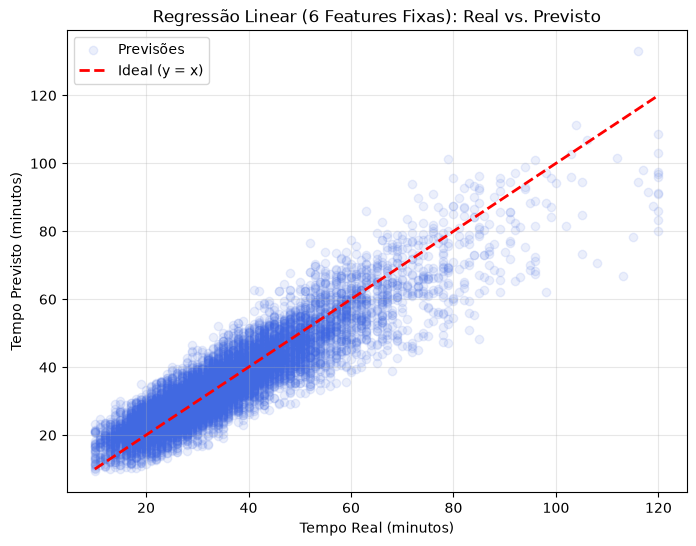

In [30]:
# ==============================================================================
# 3. VISUALIZAÇÃO DOS RESULTADOS
# ==============================================================================
# Garantindo que a pasta exista
os.makedirs('../reports/figures', exist_ok=True)

plt.figure(figsize=(8, 6))
plt.scatter(y_test_real, y_pred_real, alpha=0.1, color='royalblue', label='Previsões')
plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 
         'r--', linewidth=2, label='Ideal (y = x)')
plt.xlabel('Tempo Real (minutos)')
plt.ylabel('Tempo Previsto (minutos)')
plt.title('Regressão Linear (6 Features Fixas): Real vs. Previsto')
plt.legend()
plt.grid(True, alpha=0.3)

# SALVANDO A IMAGEM PARA O RELATÓRIO LATEX
plt.savefig('../reports/figures/regression_scatter.png', dpi=300, bbox_inches='tight')